In this notebook we decompose the difference between historial and present data in the geopotential height field in the Northern Atlantic. The decomposition is aimed at discrimating the influence of atmospheric blocking and zonal regime on the observed anomaly.
The decomposition  is the following: <br> <br>
$ z-\hat{z} = [ fz_b + (1-f)z_z ] - [ \hat{f}\hat{z_b} + (1-f)\hat{z_z} ] = (f-\hat{f})(z_b-z_z) + \hat{f}[(z_b-\hat{z_b})-(z_z-\hat{z_z})] + z_z-\hat{z_z} $ <br> <br>
where z_b is the geopotential when blocked. z_z is the zonal geopotential. ^ stays for reanalysis and no sign is for simulated. The various term of the third member are:
- frequency bias
- difference in blocking pattern
- difference in mean state

We are going to plot the various parts of the third memeber for different points.t points.

$ a = [\bar{a}] + a' + \bar{a^*} $

In [1]:
#import some basic classes
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.util as cutil
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy import stats

#my own classes
import sys
sys.path.append("/Users/michelefilippucci/Prog/github/AtmBlockPy/lib")
import BlockPlots as BP
import BlockTools as BT

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [2]:
computation = True

In [3]:
#IMPORT DATA
%cd /Users/michelefilippucci/Data/ERA5/geop
!ls

/Users/michelefilippucci/Data/ERA5
ERA5_2.5x2.5_zg500_daily_1940-2024.nc
ERA5_2m_temperature_day_r144x73_sfc_1979-2019.nc
ERA5_2mt_pr_land_12hrs_northem_2.5x2.5_1940-2023.nc
ERA5_2mt_pr_land_daily_2.5x2.5_jja_1940-2023.nc
ERA5_2mt_pr_land_daily_2.5x2.5_jja_1940-2023_deseasonalized.nc
ERA5_2mt_pr_land_daily_2.5x2.5_jja_1940-2023_detrended.nc
ERA5_2mt_pr_land_daily_northem_2.5x2.5_1940-2023.nc
ERA5_clim_snowc_0.1x0.1_1980-2000.nc
ERA5_geopotential_day_2.5x2.5_500hPa_1950-2021.nc
ERA5_northem_2.5x2.5_zg500_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg500_daily_1950-1960.nc
ERA5_northem_2.5x2.5_zg500_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg500_daily_jja_1940-2023_detrended.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_1950-1960.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_djf_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_jja_1940-2023.nc
ERA5_northem_2.5

In [4]:
reanalysis = "ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_jja_1940-2023_xdecomposition.nc"
reanalysis_zg = 'ERA5_northem_2.5x2.5_zg500_daily_jja_1940-2023_detrended.nc'
#output_prefix = "/home/michele/prog/summer_greenland_block_prel/decomposition"
ds = xr.open_dataset(reanalysis)
ds_zg = xr.open_dataset(reanalysis_zg)
lon=ds["lon"]
lat=ds["lat"]

In [5]:
#coordinates of the point where we look for blocking
region = "Greenland_IB" #you can use Europe, Atlantic_Ocean or Greenland
#plon,plat = BT.GeoAreaCoordinates(region) 
plon = -35#7.5   #Davini et D'Andrea 2016 Euro Atlantic box
plat = 70#52.5
print(plon,plat)
#grid dimension
grid = 2.5
g = 9.80665  
l_lon = 30#33.75 #edge of the box along longitude (semilato)
l_lat = 10#22.5 #edge of the box along latitude

-35 70


In [6]:
zg = ds_zg['zg'].loc[:,0:90,-180:180]
time = range(len(ds['time']))

In [7]:
'''
#detrending
#initializing zg data
zg = ds['zg'].loc[:,0:90,-180:180]
zg_1d = zg.mean(axis=1).mean(axis=1)
time = range(len(ds['time']))

# Detrend the data using a polynomial fit
degree = 1  # Degree of the polynomial (1 for linear trend, adjust as needed)
coefficients = np.polyfit(time, zg_1d, degree)
print(coefficients)
trend = np.polyval(coefficients, time)
fig,ax = plt.subplots(figsize=(6,3))
ax.plot(time,zg_1d)
ax.plot(time,trend)

arr_trend = np.zeros(zg.shape)
for t in time:
  arr_trend[t,:,:] = trend[t] + coefficients[1]
zg = zg - arr_trend
'''

"\n#detrending\n#initializing zg data\nzg = ds['zg'].loc[:,0:90,-180:180]\nzg_1d = zg.mean(axis=1).mean(axis=1)\ntime = range(len(ds['time']))\n\n# Detrend the data using a polynomial fit\ndegree = 1  # Degree of the polynomial (1 for linear trend, adjust as needed)\ncoefficients = np.polyfit(time, zg_1d, degree)\nprint(coefficients)\ntrend = np.polyval(coefficients, time)\nfig,ax = plt.subplots(figsize=(6,3))\nax.plot(time,zg_1d)\nax.plot(time,trend)\n\narr_trend = np.zeros(zg.shape)\nfor t in time:\n  arr_trend[t,:,:] = trend[t] + coefficients[1]\nzg = zg - arr_trend\n"

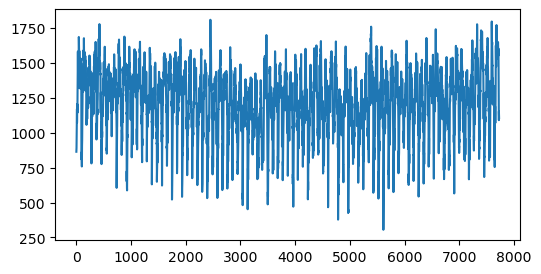

In [8]:
fig,ax = plt.subplots(figsize=(6,3))
ax.plot(time,zg.mean(axis=1).mean(axis=1))

In [9]:
#rearrange datasets
ds['zg'] = zg
ds.to_netcdf('detrended.nc')
#ds.close()
ds_tot = ds
!cdo -selyear,1960/1990 detrended.nc past.nc
!cdo -selyear,1990/2020 detrended.nc present.nc
ds_hist = xr.load_dataset('past.nc')
ds_pres = xr.load_dataset('present.nc')
!rm detrended.nc
!rm past.nc
!rm present.nc


cdo    selyear: Processed 45591696 values from 4 variables over 7728 timesteps [0.62s 145MB]
cdo    selyear: Processed 45591696 values from 4 variables over 7728 timesteps [0.70s 145MB]


In [11]:
#DATA COMPUTATION
%cd /Users/michelefilippucci/Data/ERA5
dic = np.load('dictionaries/ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_jja_1940-2023_xdecomposition_DIC.npy',allow_pickle=True)
if computation:
    for version in ("hist","pres"):
      if version == "hist":
          ds = ds_hist
      if version == "pres":
          ds = ds_pres
      N_b = 0
      N_z = 0
      zg = np.zeros(np.shape(ds["zg"].values[0,:,:]))
      zg_b = np.zeros(np.shape(ds["zg"].values[0,:,:]))
      zg_z = np.zeros(np.shape(ds["zg"].values[0,:,:]))
      comp_labels = []
      TM90 = ds["DAV_tracked"]
      for t in tqdm(range(len(ds["time"]))):
        zg += ds["zg"].values[t,:,:]
        #to convert it to boolean values
        #Pass by point w label
        bool = TM90[t,:,:].loc[plat,plon]>0
        if bool == True:
          label = TM90[t,:,:].loc[plat,plon].astype(int)
          if label not in comp_labels: #and dic[label]['distance_traveled'] < 1000000:
            time = dic[label]['time']
            persistence = dic[label]['persistence']
            N_b += persistence
            for k in range(persistence):
                zg_b += ds_tot['zg'].values[time+k,:,:]
            comp_labels.append(label)

      #compute zg in zonal days
      N_z = len(ds['time']) - N_b
      zg_z = zg-zg_b

      f_b = N_b/(N_b + N_z)
      f_z = 1-f_b
      # we have to adjust zg dimensions
      zg = zg/((N_b+N_z)*g)
      zg_b = zg_b/(N_b*g)
      zg_z = zg_z/(N_z*g)
      
      np.save("/Users/michelefilippucci/Prog/summer_greenland_block/decomposition/data/f_b_"+version+"_"+region,f_b)
      np.save("/Users/michelefilippucci/Prog/summer_greenland_block/decomposition/data/f_z_"+version+"_"+region,f_z)
      np.save("/Users/michelefilippucci/Prog/summer_greenland_block/decomposition/data/zg_"+version+"_"+region,zg)
      np.save("/Users/michelefilippucci/Prog/summer_greenland_block/decomposition/data/zg_b_"+version+"_"+region,zg_b)
      np.save("/Users/michelefilippucci/Prog/summer_greenland_block/decomposition/data/zg_z_"+version+"_"+region,zg_z)


/Users/michelefilippucci/Data/ERA5


100%|██████████████████████████████████████████████████████████████████| 2852/2852 [00:13<00:00, 209.29it/s]


In [12]:
def Bootstrap(zg,n_sample,n_iter):
    length = len(zg)
    zg_set = []
    for iter in tqdm(range(n_iter)):
        idxs = np.random.choice(np.arange(0,length,1), size=n_sample, replace=False)
        zg_set.append(zg[idxs,:,:].mean(axis=0))
    return np.array(zg_set).std(axis=0)/np.sqrt(n_sample)

In [13]:
print(f_b*len(ds['zg'].values))
zg_err = Bootstrap(ds['zg'].values,int(300),100)
print(np.amax(zg_err))


835.0


100%|███████████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 1417.49it/s]

4.243442


In [14]:
#import data

%cd /Users/michelefilippucci/Prog/summer_greenland_block/decomposition

version = "hist"
f_b_h = np.load("data/f_b_"+version+"_"+region+".npy", allow_pickle = True)
f_z_h = np.load("data/f_z_"+version+"_"+region+".npy", allow_pickle = True)
zg_h = np.load("data/zg_"+version+"_"+region+".npy", allow_pickle = True)
zg_b_h = np.load("data/zg_b_"+version+"_"+region+".npy", allow_pickle = True)
zg_z_h = np.load("data/zg_z_"+version+"_"+region+".npy", allow_pickle = True)

version = "pres"
f_b_p = np.load("data/f_b_"+version+"_"+region+".npy", allow_pickle = True)
f_z_p = np.load("data/f_z_"+version+"_"+region+".npy", allow_pickle = True)
zg_p = np.load("data/zg_"+version+"_"+region+".npy", allow_pickle = True)
zg_b_p = np.load("data/zg_b_"+version+"_"+region+".npy", allow_pickle = True)
zg_z_p = np.load("data/zg_z_"+version+"_"+region+".npy", allow_pickle = True)

print(f_b_h,f_b_p)
print(f_z_h,f_z_p)
print(zg_h.mean(axis=(0,1)),zg_p.mean(axis=(0,1)))
print(zg_b_h.mean(axis=(0,1)),zg_b_p.mean(axis=(0,1)))
print(zg_z_h.mean(axis=(0,1)),zg_z_p.mean(axis=(0,1)))

/Users/michelefilippucci/Prog/summer_greenland_block/decomposition
0.23422159887798036 0.29277699859747547
0.7657784011220197 0.7072230014025245
119.20529274783243 123.18127926862387
114.69779642409684 115.87198394205554
120.58395920582483 126.20718982771388


In [15]:
err_ph = Bootstrap(ds_tot['zg'].values,int(len(ds['zg'])),1000)
err_b = Bootstrap(ds_tot['zg'].values,int(0.25*len(ds['zg'])),1000)
err_z = Bootstrap(ds_tot['zg'].values,int(0.75*len(ds['zg'])),1000)

100%|██████████████████████████████████████████████████████████████████| 1000/1000 [00:04<00:00, 222.80it/s]


0.7311703
0.13351268


/Users/michelefilippucci/miniconda3/envs/blocktoolbox_env/lib/python3.11/site-packages/cartopy/mpl/geoaxes.py:1662: UserWarning: The following kwargs were not used by contour: 'ticks'
  result = super().contourf(*args, **kwargs)


1.0681014
1.0639796


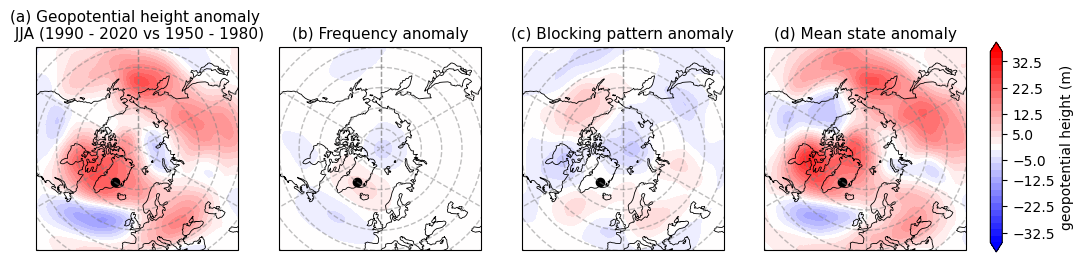

In [17]:
import numpy.ma as ma
import cartopy.util as cutil

fig,ax = plt.subplots(nrows=1,ncols=4,figsize=(12,3),subplot_kw={'projection': ccrs.AzimuthalEquidistant(central_latitude = 90)})
ax.flatten()
titles = ('(a) Geopotential height anomaly \n JJA (1990 - 2020 vs 1950 - 1980)',
          '(b) Frequency anomaly',
          '(c) Blocking pattern anomaly',
          '(d) Mean state anomaly')
fields = [zg_p-zg_h,
         (f_b_p-f_b_h)*(zg_b_p-zg_z_p),
         (f_b_h)*((zg_z_h-zg_b_h)-(zg_z_p-zg_b_p)),
         zg_z_p-zg_z_h]
'''
errs = [np.sqrt(err_ph**2*2),
        (f_b_p-f_b_h)*np.sqrt(err_b**2+err_z**2),
        (f_b_h)*np.sqrt(err_b**2*2+err_z**2*2),
        np.sqrt(err_z**2*2)]'''
errs = [(err_ph*2),
        (f_b_p-f_b_h)*(err_b+err_z),
        (f_b_h)*(err_b*2+err_z*2),
        (err_z*2)]

t_st_95 = []

for i,f in enumerate(fields):
    arr = [abs(fields[i]/errs[i])>3.261,np.abs(fields[i])>1.25]
    tmp = arr[0] & arr[1]
    t_st_95.append(cutil.add_cyclic_point(tmp))
    fields[i] = cutil.add_cyclic_point(f)
lon = np.append(ds['lon'],180-10**(-6))
#print(t_st_95[0])

#plot composite
for i,field in enumerate(fields):
    field = ma.masked_array(field,field==0)
    extent =[-180,180,40,90] 
    datacrs = ccrs.PlateCarree()
    ax[i].set_extent(extent, ccrs.PlateCarree())
    ax[i].coastlines(linewidth = 0.6)
    ax[i].plot(plon,plat,color='black', marker='o',transform=datacrs)
    gl = ax[i].gridlines(crs=ccrs.PlateCarree(), draw_labels=False,
                    linewidth=1, 
                    color='gray', 
                    alpha=0.5, 
                    linestyle='--')
    cs_range = np.arange(-36.25,+36.5,2.5)
    ticks = (-32.5,-22.5,-12.5,-5,5,12.5,22.5,32.5) #500
    print(np.amax(errs[i]))
    cont = ax[i].contourf(lon,lat,field,cs_range,
                          ticks=ticks,
                          cmap = 'bwr',
                          extent=[0,90,-180,180],
                          extend='both',
                          transform=datacrs
                          )
    #cs_p = ax[i].contourf(lon,lat,t_st_95[i],levels = 1,colors='none',hatches=['','..'],transform=datacrs)
    
    ax[i].set_title(titles[i],fontsize=11)# + " (" + str(plon) + "E," + str(plat) + "W)")
        
#plot variance

cb_label = "geopotential height (m)"
cbar_ax = fig.add_axes([0.92,0.15,0.01,0.7])
cbar = plt.colorbar(cont, cax=cbar_ax, orientation='vertical',label=cb_label,ticks=ticks,pad=0.06, aspect=60)


plt.savefig("/Users/michelefilippucci/PLOTS/EGU/decomposition_pers5filt.png",bbox_inches='tight',dpi = 300)


#plot MY DECOMPOSITION

fig = plt.figure(figsize=(22,5))

#1
dataarray_comp = xr.DataArray(data=zg_p-zg_h,dims=["lat","lon"],coords = dict(lat=lat,lon=lon))
RMS = sum(sum(dataarray_comp.loc[plat-l_lat:plat+l_lat,plon-l_lon:plon+l_lon]**2))
RMS = float(RMS)
dataarray_comp.name = "zg_an"
ds_1 = dataarray_comp.to_dataset()


ax1 = BP.PlotField(ds = ds_1,
              field="zg_an", #name of zg500 matrix, may vary from file to file
              subplot_grid = 14,
              subplot_idx = 1,
              extent =[-180,180,20,90],
              plot_title="Geopotential height anomaly")

ax1.plot(plon,plat,'ro',transform=ccrs.PlateCarree())

#2
dataarray_comp = xr.DataArray(data=(f_b_p-f_b_h)*(+zg_b_p-zg_z_p),dims=["lat","lon"],coords = dict(lat=lat,lon=lon))
RMS = sum(sum(dataarray_comp.loc[plat-l_lat:plat+l_lat,plon-l_lon:plon+l_lon]**2))
RMS = float(RMS)
dataarray_comp.name = "zg_an"
ds_2 = dataarray_comp.to_dataset()

ax2 = BP.PlotField(ds = ds_2,
              field="zg_an", #name of zg500 matrix, may vary from file to file
              subplot_grid = 14,
              subplot_idx = 2,
              extent =[-180,180,20,90],
              plot_title="Frequency anomaly")

ax2.plot(plon,plat,'ro',transform=ccrs.PlateCarree())

#3
dataarray_comp = xr.DataArray(data=(f_b_h)*(zg_b_p-zg_b_h),dims=["lat","lon"],coords = dict(lat=lat,lon=lon))
RMS = sum(sum(dataarray_comp.loc[plat-l_lat:plat+l_lat,plon-l_lon:plon+l_lon]**2))
RMS = float(RMS)
dataarray_comp.name = "zg_an"
ds_3 = dataarray_comp.to_dataset()

ax3 = BP.PlotField(ds = ds_3,
              field="zg_an", #name of zg500 matrix, may vary from file to file
              subplot_grid = 14,
              subplot_idx = 3,
              extent =[-180,180,20,90],
              plot_title="Blocking pattern anomaly")

ax3.plot(plon,plat,'ro',transform=ccrs.PlateCarree())


#4
dataarray_comp = xr.DataArray(data=f_z_h*(zg_z_p-zg_z_h),dims=["lat","lon"],coords = dict(lat=lat,lon=lon))
RMS = sum(sum(dataarray_comp.loc[plat-l_lat:plat+l_lat,plon-l_lon:plon+l_lon]**2))
RMS = float(RMS)
dataarray_comp.name = "zg_an"
ds_4 = dataarray_comp.to_dataset()

ax4 = BP.PlotField(ds = ds_4,
              field="zg_an", #name of zg500 matrix, may vary from file to file
              subplot_grid = 14,
              subplot_idx = 4,
              extent =[-180,180,20,90],
              plot_title="Mean state anomaly")

ax4.plot(plon,plat,'ro',transform=ccrs.PlateCarree())

#plt.show()
#plt.savefig("/Users/michelefilippucci/Pictures/PLOTS/decomposition.png",bbox_inches='tight',dpi = 400)

#plt.savefig(output_prefix + region + "_mas-mab_comparison.pdf",bbox_inches='tight',dpi=250)

#plot #DECOMPOSITION FROM DAVINI ET AL.

fig = plt.figure(figsize=(22,5))

#1
dataarray_comp = xr.DataArray(data=zg_p-zg_h,dims=["lat","lon"],coords = dict(lat=lat,lon=lon))
RMS = sum(sum(dataarray_comp.loc[plat-l_lat:plat+l_lat,plon-l_lon:plon+l_lon]**2))
RMS = float(RMS)
dataarray_comp.name = "zg_an"
ds_1 = dataarray_comp.to_dataset()


ax1 = BP.PlotField(ds = ds_1,
              field="zg_an", #name of zg500 matrix, may vary from file to file
              subplot_grid = 14,
              subplot_idx = 1,
              extent =[-180,180,20,90],
              plot_title="Geopotential height anomaly")

ax1.plot(plon,plat,'ro',transform=ccrs.PlateCarree())

#2
dataarray_comp = xr.DataArray(data=(-f_b_h+f_b_p)*(+zg_b_p-zg_z_p),dims=["lat","lon"],coords = dict(lat=lat,lon=lon))
RMS = sum(sum(dataarray_comp.loc[plat-l_lat:plat+l_lat,plon-l_lon:plon+l_lon]**2))
RMS = float(RMS)
dataarray_comp.name = "zg_an"
ds_2 = dataarray_comp.to_dataset()

ax2 = BP.PlotField(ds = ds_2,
              field="zg_an", #name of zg500 matrix, may vary from file to file
              subplot_grid = 14,
              subplot_idx = 2,
              extent =[-180,180,20,90],
              plot_title="Frequency anomaly")

ax2.plot(plon,plat,'ro',transform=ccrs.PlateCarree())

#3
dataarray_comp = xr.DataArray(data=(f_b_h)*((zg_z_h-zg_b_h)-(zg_z_p-zg_b_p)),dims=["lat","lon"],coords = dict(lat=lat,lon=lon))
RMS = sum(sum(dataarray_comp.loc[plat-l_lat:plat+l_lat,plon-l_lon:plon+l_lon]**2))
RMS = float(RMS)
dataarray_comp.name = "zg_an"
ds_3 = dataarray_comp.to_dataset()

ax3 = BP.PlotField(ds = ds_3,
              field="zg_an", #name of zg500 matrix, may vary from file to file
              subplot_grid = 14,
              subplot_idx = 3,
              extent =[-180,180,20,90],
              plot_title="Blocking pattern anomaly")

ax3.plot(plon,plat,'ro',transform=ccrs.PlateCarree())


#4
dataarray_comp = xr.DataArray(data=zg_z_p-zg_z_h,dims=["lat","lon"],coords = dict(lat=lat,lon=lon))
RMS = sum(sum(dataarray_comp.loc[plat-l_lat:plat+l_lat,plon-l_lon:plon+l_lon]**2))
RMS = float(RMS)
dataarray_comp.name = "zg_an"
ds_4 = dataarray_comp.to_dataset()

ax4 = BP.PlotField(ds = ds_4,
              field="zg_an", #name of zg500 matrix, may vary from file to file
              subplot_grid = 14,
              subplot_idx = 4,
              extent =[-180,180,20,90],
              plot_title="Mean state anomaly")

ax4.plot(plon,plat,'ro',transform=ccrs.PlateCarree())

#plt.show()
#plt.savefig("/Users/michelefilippucci/Pictures/PLOTS/decomposition.png",bbox_inches='tight',dpi = 400)

#plt.savefig(output_prefix + region + "_mas-mab_comparison.pdf",bbox_inches='tight',dpi=250)

#THREE TERMS DECOMPOSITION

fig = plt.figure(figsize=(18,5))

#1
dataarray_comp = xr.DataArray(data=zg_p-zg_h,dims=["lat","lon"],coords = dict(lat=lat,lon=lon))
RMS = sum(sum(dataarray_comp.loc[plat-l_lat:plat+l_lat,plon-l_lon:plon+l_lon]**2))
RMS = float(RMS)
dataarray_comp.name = "zg_an"
ds_1 = dataarray_comp.to_dataset()


ax1 = BP.PlotField(ds = ds_1,
              field="zg_an", #name of zg500 matrix, may vary from file to file
              subplot_grid = 13,
              subplot_idx = 1,
              extent =[-120,60,20,90],
              plot_title="Geopotential height anomaly")

ax1.plot(plon,plat,'ro',transform=ccrs.PlateCarree())

#2
dataarray_comp = xr.DataArray(data=(f_b_p-f_b_h)*(+zg_b_p-zg_z_p) + (f_b_h)*(zg_b_p-zg_b_h),dims=["lat","lon"],coords = dict(lat=lat,lon=lon))
RMS = sum(sum(dataarray_comp.loc[plat-l_lat:plat+l_lat,plon-l_lon:plon+l_lon]**2))
RMS = float(RMS)
dataarray_comp.name = "zg_an"
ds_2 = dataarray_comp.to_dataset()

ax2 = BP.PlotField(ds = ds_2,
              field="zg_an", #name of zg500 matrix, may vary from file to file
              subplot_grid = 13,
              subplot_idx = 2,
              extent =[-120,60,20,90],
              plot_title="Blocked days")

ax2.plot(plon,plat,'ro',transform=ccrs.PlateCarree())

#3
dataarray_comp = xr.DataArray(data=f_z_h*(zg_z_p-zg_z_h),dims=["lat","lon"],coords = dict(lat=lat,lon=lon))
RMS = sum(sum(dataarray_comp.loc[plat-l_lat:plat+l_lat,plon-l_lon:plon+l_lon]**2))
RMS = float(RMS)
dataarray_comp.name = "zg_an"
ds_3 = dataarray_comp.to_dataset()

ax3 = BP.PlotField(ds = ds_3,
              field="zg_an", #name of zg500 matrix, may vary from file to file
              subplot_grid = 13,
              subplot_idx = 3,
              extent =[-120,60,20,90],
              plot_title="Non-blocked days")

ax3.plot(plon,plat,'ro',transform=ccrs.PlateCarree())

#plt.show()
#plt.savefig("/Users/michelefilippucci/Pictures/PLOTS/decomposition.png",bbox_inches='tight',dpi = 400)

#plt.savefig(output_prefix + region + "_mas-mab_comparison.pdf",bbox_inches='tight',dpi=250)